In [20]:
# Welcome to Elixir IDE Notebook
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

print('Notebook ready!')

Notebook ready!

In [31]:
df = pd.read_csv("/data/CC GENERAL.csv")
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [32]:
df.isnull().sum()

CUST_ID                               0

BALANCE                               0

BALANCE_FREQUENCY                     0

PURCHASES                             0

ONEOFF_PURCHASES                      0

INSTALLMENTS_PURCHASES                0

... (9 outputs left out)

MINIMUM_PAYMENTS                    313

PRC_FULL_PAYMENT                      0

TENURE                                0

dtype: int64

In [33]:
df.isnull().sum().sum()

314

In [34]:
x = df.select_dtypes(include=["float64", "int64"])
x = x.fillna(0)
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
print("Data scaled successfully!")

Data scaled successfully!

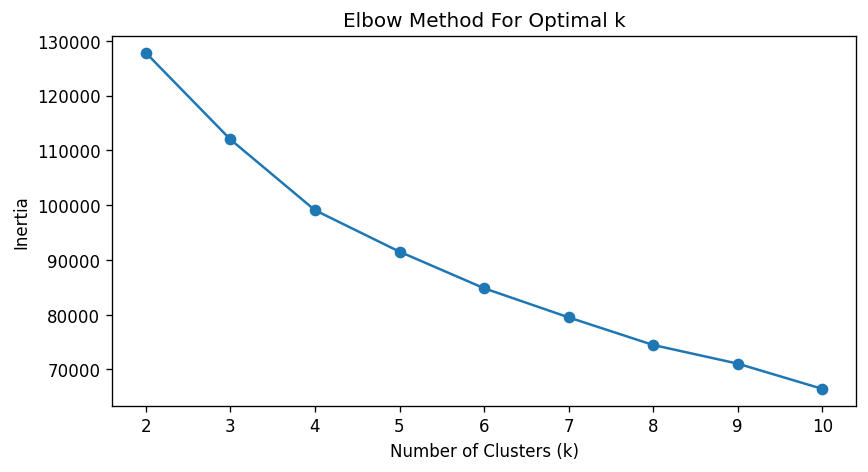

In [35]:
inertia = []
K_range = range(2, 11)

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=42)
  kmeans.fit(x_scaled)
  inertia.append(kmeans.inertia_)

# Graph plot karein
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method For Optimal k")
plt.show()

In [36]:
# Man lijiye best k = 3 select kiya hai
kmeans = KMeans(n_clusters=3, random_state=42)
df["Cluster"] = kmeans.fit_predict(x_scaled)

print(df[["Cluster"]].head())

   Cluster

0        2

1        0

2        2

3        2

4        2

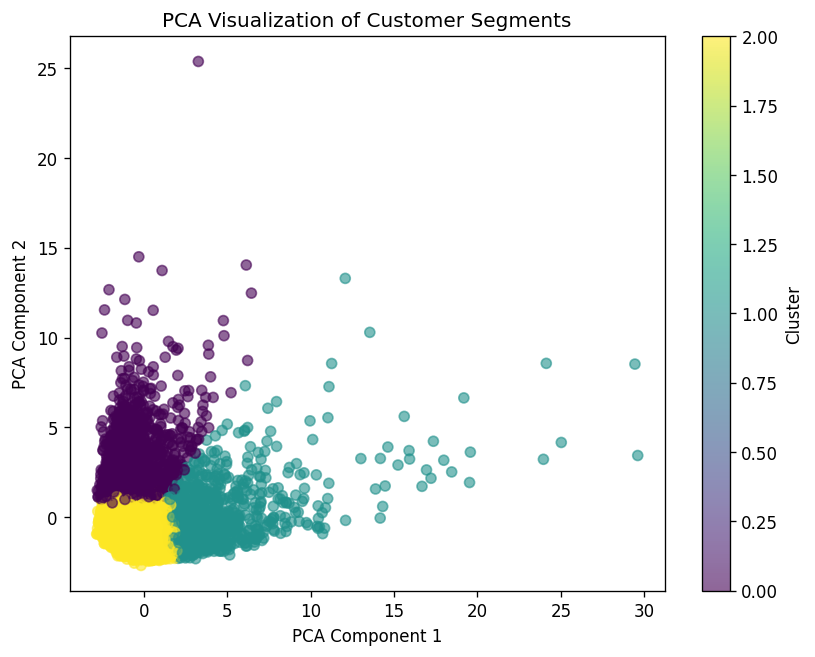

In [37]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scaled)

# Plotting PCA
plt.figure(figsize=(8, 6))
plt.scatter(
    x_pca[:, 0], x_pca[:, 1], c=df["Cluster"], cmap="viridis", alpha=0.6
)
plt.title("PCA Visualization of Customer Segments")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster")
plt.show()

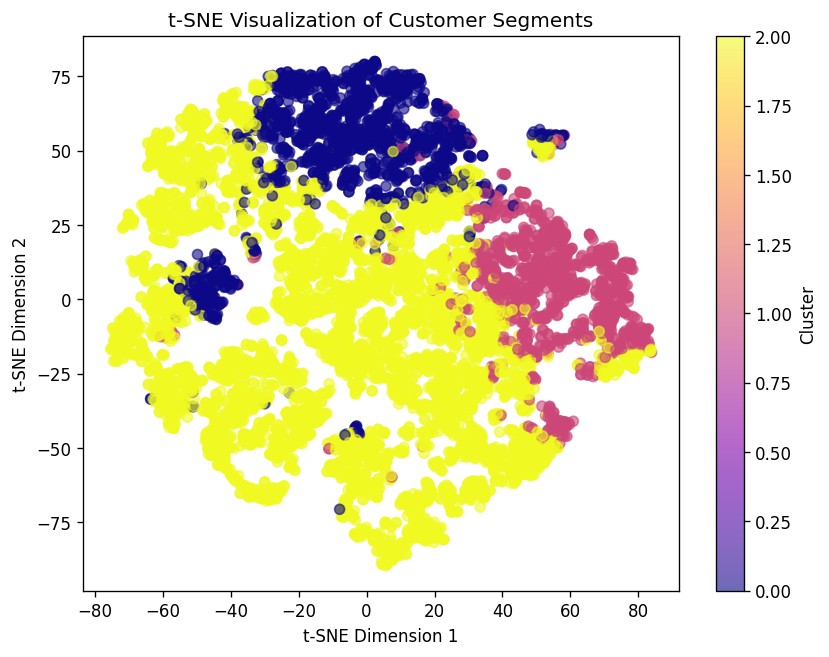

In [38]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
x_tsne = tsne.fit_transform(x_scaled)

# Plotting t-SNE
plt.figure(figsize=(8, 6))
plt.scatter(
    x_tsne[:, 0], x_tsne[:, 1], c=df["Cluster"], cmap="plasma", alpha=0.6
)
plt.title("t-SNE Visualization of Customer Segments")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.colorbar(label="Cluster")
plt.show()

In [49]:
df.to_csv("CC_GENERAL_kmeans_clusters.csv", index=False)
print("Final clusters saved successfully to file!")

Final clusters saved successfully to file!